<a href="https://colab.research.google.com/github/Caleb-John1603/AI_5th_sem/blob/main/WEEK%2010_%20ALPHA%20BETA%20PRUNING.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

INPUT FORMATS:
1. Nested list
2. Branching factor + leaf values
3. Named dictionary
Choose format [1/2/3] (default 1): 3
Enter tree: {"R": {"L": {"L1": {"a": 10, "b": 9}, "L2": {"c": 14, "d": 18}}, "Rt": {"R1": {"e": 5, "f": 4}, "R2": {"g": 50, "h": 3}}}}
Root type MAX/MIN (default MAX): MAX

ROOT VALUE: 10
OPTIMAL PATH: R → L → L1 → a
PRUNED SUBTREES: d, R2
LEAVES EVALUATED: 5 / 8


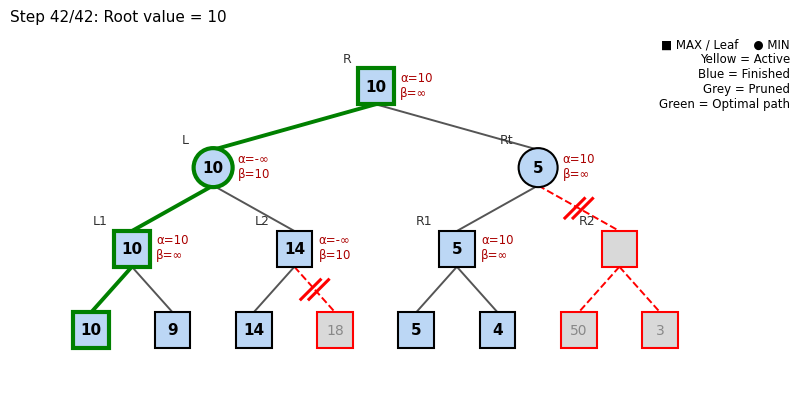

interactive(children=(IntSlider(value=0, description='Step', layout=Layout(width='80%'), max=42), Output()), _…

(10,
 [0, 1, 2, 3],
 ['Visit R (α=-∞, β=∞)',
  'Visit L (α=-∞, β=∞)',
  'Visit L1 (α=-∞, β=∞)',
  'Visit a (α=-∞, β=∞)',
  'a is terminal → value 10',
  'L1: child a returned 10 → value=10',
  'L1: α=10, β=∞',
  'Visit b (α=10, β=∞)',
  'b is terminal → value 9',
  'L1: child b returned 9 → value=10',
  'L1: α=10, β=∞',
  'L1 returns 10',
  'L: child L1 returned 10 → value=10',
  'L: α=-∞, β=10',
  'Visit L2 (α=-∞, β=10)',
  'Visit c (α=-∞, β=10)',
  'c is terminal → value 14',
  'L2: child c returned 14 → value=14',
  'PRUNE under L2: 14 >= β=10',
  'L2 returns 14',
  'L: child L2 returned 14 → value=10',
  'L: α=-∞, β=10',
  'L returns 10',
  'R: child L returned 10 → value=10',
  'R: α=10, β=∞',
  'Visit Rt (α=10, β=∞)',
  'Visit R1 (α=10, β=∞)',
  'Visit e (α=10, β=∞)',
  'e is terminal → value 5',
  'R1: child e returned 5 → value=5',
  'R1: α=10, β=∞',
  'Visit f (α=10, β=∞)',
  'f is terminal → value 4',
  'R1: child f returned 4 → value=5',
  'R1: α=10, β=∞',
  'R1 returns 5',


In [2]:

import math
import copy
import ast
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle

INF = math.inf

def fmt(x):
    if x == -INF:
        return "-∞"
    if x == INF:
        return "∞"
    return str(int(x)) if float(x).is_integer() else f"{x:g}"


# ---------------- NODE CLASS ----------------

class Node:
    def __init__(self, name=None, is_max=True, leaf=None):
        self.name = name
        self.is_max = is_max
        self.leaf = leaf
        self.children = []
        self.x = 0
        self.y = 0
        self.id = None

    @property
    def is_leaf(self):
        return self.leaf is not None


# ---------------- BUILD TREE ----------------

def build(obj, name, is_max):

    if isinstance(obj, (int, float)):
        return Node(name, is_max, leaf=obj)

    node = Node(name, is_max)

    if isinstance(obj, dict):
        node.children = [
            build(v, k, not is_max)
            for k, v in obj.items()
        ]

    elif isinstance(obj, (list, tuple)):
        node.children = [
            build(c, None, not is_max)
            for c in obj
        ]

    else:
        raise ValueError(f"Unsupported node: {obj!r}")

    return node


def parse(tree, root_type="MAX"):

    is_max = root_type.upper() == "MAX"

    if (
        isinstance(tree, dict)
        and len(tree) == 1
        and isinstance(list(tree.values())[0], (dict, list))
    ):
        (name, value), = tree.items()
        root = build(value, name, is_max)
    else:
        root = build(tree, None, is_max)

    nodes = []
    leaves = [0]

    def layout(node, depth):

        node.id = len(nodes)
        nodes.append(node)
        node.y = -depth

        for child in node.children:
            layout(child, depth + 1)

        if node.is_leaf:
            node.x = leaves[0]
            leaves[0] += 1
        else:
            node.x = sum(c.x for c in node.children) / len(node.children)

    layout(root, 0)

    return root, nodes


# ---------------- ALPHA BETA ALGORITHM ----------------

def alpha_beta(root, nodes):

    state = {
        n.id: {
            "status": "unvisited",
            "value": None,
            "alpha": None,
            "beta": None,
            "cut": []
        }
        for n in nodes
    }

    snapshots = []
    log = []

    def label(n):
        if n.name:
            return n.name

        if n.is_leaf:
            return f"leaf {fmt(n.leaf)}"

        return f"{'MAX' if n.is_max else 'MIN'}#{n.id}"

    def snap(message, active=None):
        snapshots.append((message, copy.deepcopy(state), active))
        log.append(message)

    def mark_pruned(node):

        state[node.id]["status"] = "pruned"

        for child in node.children:
            mark_pruned(child)

    def search(node, alpha, beta):

        s = state[node.id]

        s.update(
            status="active",
            alpha=alpha,
            beta=beta
        )

        snap(
            f"Visit {label(node)} (α={fmt(alpha)}, β={fmt(beta)})",
            node.id
        )

        if node.is_leaf:

            s.update(
                status="done",
                value=node.leaf
            )

            snap(
                f"{label(node)} is terminal → value {fmt(node.leaf)}",
                node.id
            )

            return node.leaf

        value = -INF if node.is_max else INF

        for i, child in enumerate(node.children):

            child_value = search(child, alpha, beta)

            if node.is_max:
                value = max(value, child_value)
            else:
                value = min(value, child_value)

            s["value"] = value

            snap(
                f"{label(node)}: child {label(child)} "
                f"returned {fmt(child_value)} → value={fmt(value)}",
                node.id
            )

            # MAX NODE
            if node.is_max:

                if value >= beta:

                    remaining = node.children[i + 1:]

                    for r in remaining:
                        mark_pruned(r)

                    s["cut"] = [r.id for r in remaining]

                    if remaining:
                        snap(
                            f"PRUNE under {label(node)}: "
                            f"{fmt(value)} >= β={fmt(beta)}",
                            node.id
                        )

                    break

                alpha = max(alpha, value)

            # MIN NODE
            else:

                if value <= alpha:

                    remaining = node.children[i + 1:]

                    for r in remaining:
                        mark_pruned(r)

                    s["cut"] = [r.id for r in remaining]

                    if remaining:
                        snap(
                            f"PRUNE under {label(node)}: "
                            f"{fmt(value)} <= α={fmt(alpha)}",
                            node.id
                        )

                    break

                beta = min(beta, value)

            s.update(
                alpha=alpha,
                beta=beta
            )

            snap(
                f"{label(node)}: α={fmt(alpha)}, β={fmt(beta)}",
                node.id
            )

        s.update(status="done", value=value)

        snap(
            f"{label(node)} returns {fmt(value)}",
            node.id
        )

        return value

    # Start search
    root_value = search(root, -INF, INF)

    # Find optimal path
    path = [root.id]
    node = root

    while not node.is_leaf:

        next_node = next(
            child for child in node.children
            if state[child.id]["status"] == "done"
            and state[child.id]["value"] == state[node.id]["value"]
        )

        path.append(next_node.id)
        node = next_node

    snap(f"Root value = {fmt(root_value)}", root.id)

    return root_value, path, snapshots, log, state


# ---------------- DRAW TREE ----------------

COLORS = {
    "unvisited": "#ffffff",
    "active": "#ffe45c",
    "done": "#bcd7f5",
    "pruned": "#d9d9d9"
}


def draw(nodes, snapshots, path, step):

    message, state, active = snapshots[step]

    final = step == len(snapshots) - 1

    xs = [n.x for n in nodes]
    ys = [n.y for n in nodes]

    width = max(8, (max(xs) - min(xs) + 2) * 0.9)
    height = max(5, (max(ys) - min(ys) - 1) * -1.9 + 2)

    fig, ax = plt.subplots(
        figsize=(min(width, 22), min(height, 12))
    )

    ax.set_aspect("equal")
    ax.axis("off")

    path_edges = set(zip(path, path[1:]))

    # Draw edges
    for node in nodes:

        for child in node.children:

            pruned = state[child.id]["status"] == "pruned"

            on_path = (
                final and
                (node.id, child.id) in path_edges
            )

            if pruned:
                color = "red"
            elif on_path:
                color = "green"
            else:
                color = "#555555"

            ax.plot(
                [node.x, child.x],
                [node.y - 0.22, child.y + 0.22],
                color=color,
                linewidth=2.8 if on_path else 1.4,
                linestyle="--" if pruned else "-",
                zorder=1
            )

            if (
                pruned
                and state[node.id]["cut"]
                and child.id == min(state[node.id]["cut"])
            ):
                mx = (node.x + child.x) / 2
                my = (node.y + child.y) / 2

                for dx in (-0.05, 0.05):
                    ax.plot(
                        [mx - 0.12 + dx, mx + 0.12 + dx],
                        [my - 0.12, my + 0.12],
                        color="red",
                        linewidth=2.2,
                        zorder=3
                    )

    # Draw nodes
    for node in nodes:

        s = state[node.id]

        face = COLORS[s["status"]]

        edge = (
            "green" if final and node.id in path
            else "red" if s["status"] == "pruned"
            else "black"
        )

        lw = 3 if final and node.id in path else 1.5

        if node.is_max or node.is_leaf:

            ax.add_patch(
                Rectangle(
                    (node.x - 0.22, node.y - 0.22),
                    0.44,
                    0.44,
                    facecolor=face,
                    edgecolor=edge,
                    linewidth=lw,
                    zorder=2
                )
            )

        else:

            ax.add_patch(
                Circle(
                    (node.x, node.y),
                    0.24,
                    facecolor=face,
                    edgecolor=edge,
                    linewidth=lw,
                    zorder=2
                )
            )

        if s["value"] is not None:

            ax.text(
                node.x,
                node.y,
                fmt(s["value"]),
                ha="center",
                va="center",
                fontsize=11,
                fontweight="bold",
                zorder=4
            )

        elif s["status"] == "pruned" and node.is_leaf:

            ax.text(
                node.x,
                node.y,
                fmt(node.leaf),
                ha="center",
                va="center",
                fontsize=10,
                color="#888888",
                zorder=4
            )

        if node.name and not node.is_leaf:

            ax.text(
                node.x - 0.3,
                node.y + 0.3,
                node.name,
                fontsize=9,
                color="#333333",
                ha="right"
            )

        if not node.is_leaf and s["alpha"] is not None:

            ax.text(
                node.x + 0.3,
                node.y + 0.02,
                f"α={fmt(s['alpha'])}\nβ={fmt(s['beta'])}",
                fontsize=8.5,
                color="#aa0000",
                va="center",
                ha="left",
                zorder=4,
                bbox=dict(
                    facecolor="white",
                    edgecolor="none",
                    alpha=0.7,
                    pad=0.5
                )
            )

    ax.set_xlim(min(xs) - 1, max(xs) + 1.6)
    ax.set_ylim(min(ys) - 0.7, max(ys) + 0.7)

    ax.set_title(
        f"Step {step}/{len(snapshots)-1}: {message}",
        fontsize=11,
        loc="left"
    )

    ax.text(
        max(xs) + 1.6,
        max(ys) + 0.6,
        "■ MAX / Leaf    ● MIN\n"
        "Yellow = Active\n"
        "Blue = Finished\n"
        "Grey = Pruned\n"
        "Green = Optimal path",
        fontsize=8.5,
        va="top",
        ha="right"
    )

    plt.tight_layout()
    plt.show()


# ---------------- SOLVE FUNCTION ----------------

def solve(tree, root_type="MAX", interactive=True):

    root, nodes = parse(tree, root_type)

    value, path, snapshots, log, state = alpha_beta(
        root, nodes
    )

    last = len(snapshots) - 1

    pruned = [
        n for n in nodes
        if state[n.id]["status"] == "pruned"
        and not any(
            state[p.id]["status"] == "pruned"
            and n in p.children
            for p in nodes
        )
    ]

    def node_name(i):

        n = nodes[i]

        if n.name:
            return n.name

        if n.is_leaf:
            return fmt(n.leaf)

        return f"{'MAX' if n.is_max else 'MIN'}#{i}"

    print("\nROOT VALUE:", fmt(value))

    print(
        "OPTIMAL PATH:",
        " → ".join(node_name(i) for i in path)
    )

    print(
        "PRUNED SUBTREES:",
        ", ".join(node_name(n.id) for n in pruned)
        or "None"
    )

    evaluated = sum(
        1 for n in nodes
        if n.is_leaf and state[n.id]["status"] == "done"
    )

    total = sum(1 for n in nodes if n.is_leaf)

    print(f"LEAVES EVALUATED: {evaluated} / {total}")

    draw(nodes, snapshots, path, last)

    # Interactive step slider
    if interactive:

        try:
            import ipywidgets as widgets

            widgets.interact(
                lambda step: draw(
                    nodes, snapshots, path, step
                ),
                step=widgets.IntSlider(
                    value=0,
                    min=0,
                    max=last,
                    step=1,
                    description="Step",
                    layout=widgets.Layout(width="80%")
                )
            )

        except ImportError:
            print("Install ipywidgets for step-by-step visualization.")

    return value, path, log


# ---------------- USER INPUT ----------------

def build_uniform(branching, leaves):

    it = iter(leaves)

    def rec(depth):

        if depth == len(branching):
            return next(it)

        return [
            rec(depth + 1)
            for _ in range(branching[depth])
        ]

    return rec(0)


print("INPUT FORMATS:")
print("1. Nested list")
print("2. Branching factor + leaf values")
print("3. Named dictionary")

choice = input("Choose format [1/2/3] (default 1): ").strip() or "1"

if choice == "2":

    branching = [
        int(x)
        for x in input(
            "Branching factor per level: "
        ).split()
    ]

    leaves = [
        float(x) if "." in x else int(x)
        for x in input(
            "Leaf values left to right: "
        ).split()
    ]

    tree = build_uniform(branching, leaves)

else:

    tree = ast.literal_eval(
        input("Enter tree: ")
    )

root_type = (
    input("Root type MAX/MIN (default MAX): ")
    .strip()
    .upper() or "MAX"
)

solve(tree, root_type)